In [1]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
from statsmodels.api import OLS
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from ISLP import load_data
from ISLP.models import ModelSpec as MS
from functools import partial

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from ISLP.models import \
(Stepwise,
sklearn_selected,
sklearn_selection_path)
!pip install l0bnb
from l0bnb import fit_path

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for l0bnb: filename=l0bnb-1.0.0-py3-none-any.whl size=22405 sha256=13fb41f4dd99abf9fb67fc4dc3f34e30816320d197e1b4b5a4fed6f567d6cc4f
  Stored in directory: c:\users\fatima zahra\appdata\local\pip\cache\wheels\ec\e0\1d\fc5db86912830a11a00b6bcb57c7bb84456e3b97cea4b4d570
Successfully built l0bnb


Exercises:

Conceptual:

(a)

Smallest Training RSS for size k: Best Subset Selection will always have the smallest (or equal) training RSS compared to Forward and Backward Stepwise selection

Forward vs. Backward Stepwise might find the absolute optimal subset for a given $k$, or they might get trapped in a local optimum due to their greedy search rules. Thus, Best Subset guarantees an RSS that is less than or equal to the RSS of the stepwise methods for any given $k$.

(b)

We cannot tell which method will have the smallest test RSS. Best Subset might overfit the training data and perform worse on test data, or it might identify the true underlying model and perform better. The outcome depends entirely on the true data-generating process and the noise level in the dataset.

(c)

i:   True
ii:  True 
iii: False 
iv:  False
v:   False 

Exercise 2:

**(a) The Lasso relative to Least Squares: (iii)**

By introducing a small increase in bias, Lasso significantly reduces variance. Prediction accuracy improves when the increase in bias is smaller than the decrease in variance.


**(b) Ridge Regression relative to Least Squares: (iii)**

Bias-Variance Trade-off: Like Lasso, Ridge trades a minor increase in bias for a substantial reduction in variance. Prediction accuracy improves when the increase in bias is less than the decrease in variance.


**(c) Non-Linear Methods relative to Least Squares: (ii)**

Bias-Variance Trade-off:** Greater flexibility drastically reduces bias but increases model variance. Prediction accuracy improves when the increase in variance is less than the reduction in bias.



Exercise 3:

**(a) Training RSS: iv. Steadily decrease**

**Reasoning:** Expanding $s$ relaxes restrictions on parameters, allowing the model to fit the training data more closely and reducing training error monotonically.



**(b) Test RSS: ii. Decrease initially, and then eventually start increasing in a U shape**

**Reasoning:** Starting at $s = 0$ (high bias, zero variance), increasing $s$ reduces significant bias, lowering test error. Past an optimal point, high variance takes over as the model overfits, causing test RSS to rise again in a U-shape.



**(c) Variance: iii. Steadily increase**

**Reasoning:** Higher flexibility allows the model to become more sensitive to random noise and fluctuations in the training set.


**(d) (Squared) Bias: iv. Steadily decrease**

**Reasoning:** Allowing coefficients greater freedom lets the model capture true underlying relationships better, reducing systematic error (bias).


**(e) Irreducible Error: v. Remain constant**

**Reasoning:** Irreducible error is intrinsic noise in the data generation process and cannot be affected by parameter tuning or model choice.


Exercise 4:

**(a) Training RSS: iii. Steadily increase**

**Reasoning:** At $\lambda = 0$, the Ordinary Least Squares (OLS) fit directly minimizes training RSS. As $\lambda$ increases, the penalty forces coefficients away from their OLS values toward zero, restricting flexibility and continuously increasing training RSS.



**(b) Test RSS: ii. Decrease initially, and then eventually start increasing in a U shape**

**Reasoning:** At $\lambda = 0$, OLS can overfit due to high variance. Increasing $\lambda$ initially reduces variance significantly with only a slight increase in bias, dropping test RSS. Past the optimal $\lambda$, heavy shrinkage causes high bias, raising test RSS again in a U-shape.



**(c) Variance: iv. Steadily decrease**

**Reasoning:** Restricting parameter freedom reduces the model's sensitivity to random sample fluctuations. As $\lambda \to \infty$, all $\beta_j \to 0$, and variance approaches zero.



**(d) (Squared) Bias: iii. Steadily increase**

**Reasoning:** Forcing coefficients toward zero reduces the model's capacity to represent the true underlying relationship in the data, steadily increasing systematic bias.



**(e) Irreducible Error: v. Remain constant**

**Reasoning:** Irreducible error represents intrinsic noise in the data-generating process and is unaffected by tuning parameters or model fitting.


Exercise 5

(a)

n = 2, p = 2, $\hat{\beta}_0 = 0$

Identical predictor values: $x_{11} = x_{12} = x_1$ and $x_{21} = x_{22} = x_2$

Zero-centered conditions: $y_1 + y_2 = 0$, and $x_{11} + x_{21} = 0$


The model prediction for observation $i$ is:


$\hat{y}_i = \beta_1 x_{i1} + \beta_2 x_{i2} = (\beta_1 + \beta_2) x_{i1}$

$\text{RSS} = (y_1 - (\beta_1 + \beta_2)x_1)^2 + (y_2 - (\beta_1 + \beta_2)x_2)^2$

$\text{RSS} = (y_1 - (\beta_1 + \beta_2)x_1)^2 + (-y_1 + (\beta_1 + \beta_2)x_1)^2 = 2\left(y_1 - (\beta_1 + \beta_2)x_1\right)^2$

Substituting RSS into the Ridge Regression optimization equation yields:

$$\min_{\beta_1, \beta_2} \left\{ 2\left(y_1 - (\beta_1 + \beta_2)x_1\right)^2 + \lambda (\beta_1^2 + \beta_2^2) \right\}$$

(b)

From (a), the Ridge objective function to minimize is:


$f(\beta_1, \beta_2) = 2\left(y_1 - (\beta_1 + \beta_2)x_1\right)^2 + \lambda (\beta_1^2 + \beta_2^2)$

Taking partial derivatives with respect to $\beta_1$ and $\beta_2$, and setting them to $0$:

*Derivative with respect to $\beta_1$:*

$\frac{\partial f}{\partial \beta_1} = -4x_1\left(y_1 - (\beta_1 + \beta_2)x_1\right) + 2\lambda\beta_1 = 0$

$2\lambda\hat{\beta}_1 = 4x_1\left(y_1 - (\hat{\beta}_1 + \hat{\beta}_2)x_1\right)$


*Derivative with respect to $\beta_2$:*

$\frac{\partial f}{\partial \beta_2} = -4x_1\left(y_1 - (\beta_1 + \beta_2)x_1\right) + 2\lambda\beta_2 = 0$

$2\lambda\hat{\beta}_2 = 4x_1\left(y_1 - (\hat{\beta}_1 + \hat{\beta}_2)x_1\right)$

$2\lambda\hat{\beta}_1 = 2\lambda\hat{\beta}_2$

Dividing by $2\lambda$ (since $\lambda > 0$):


$\hat{\beta}_1 = \hat{\beta}_2$


(c)


From Part (a), the Residual Sum of Squares RSS for n=2 zero-centered observations with identical predictors simplifies to:


RSS = $$2\left(y_1 - (\beta_1 + \beta_2)x_1\right)^2$$


Substituting this RSS and the $L_1$ regularization penalty $\lambda (\vert{}\beta_1\vert{} + \vert{}\beta_2\vert{})$ into the Lasso objective function yields:

$$\min_{\beta_1, \beta_2} \left\{ 2\left(y_1 - (\beta_1 + \beta_2)x_1\right)^2 + \lambda (\vert{}\beta_1\vert{} + \vert{}\beta_2\vert{}) \right\}$$


(d)

**Proof of Non-Uniqueness:**

*RSS Dependence:* 
The Residual Sum of Squares depends strictly on the sum of the coefficients, $S = \beta_1 + \beta_2$. Let $S^*$ be the optimal combined value that minimizes the overall objective function. Any pair $(\hat{\beta}_1, \hat{\beta}_2)$ satisfying $\hat{\beta}_1 + \hat{\beta}_2 = S^*$ yields the exact same minimal RSS.


$\vert{}\hat{\beta}_1\vert{} + \vert{}\hat{\beta}_2\vert{} = \hat{\beta}_1 + \hat{\beta}_2 = S^*$



Because this sum is fixed at $S^*$, the penalty

$\lambda(\vert{}\hat{\beta}_1\vert{} + \vert{}\hat{\beta}_2\vert{}) = \lambda S^*$

remains constant regardless of how $S^*$ is split between $\hat{\beta}_1$ and $\hat{\beta}_2$.


Exercise 6:

C:\Users\Fatima zahra\AppData\Local\Temp\ipykernel_15340\391686562.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=11)


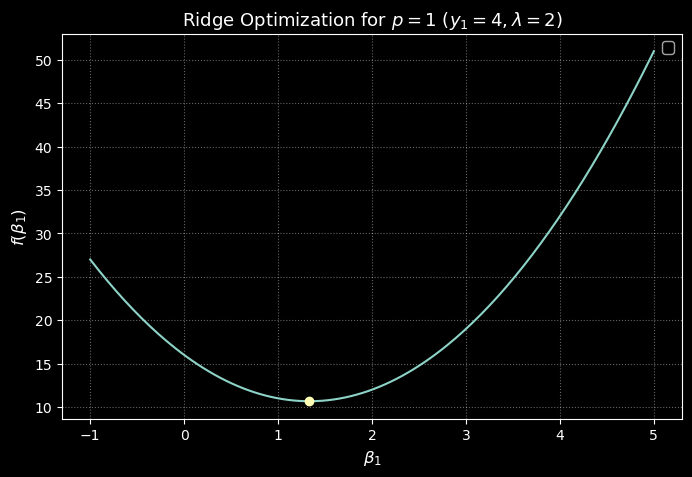

In [21]:
#(a)

import matplotlib.pyplot as plt
import numpy as np

y1 = 4
lambda_param = 2
beta1_opt = y1 / (1 + lambda_param)  
f_opt = (y1 - beta1_opt) ** 2 + lambda_param * (beta1_opt**2)  
beta1 = np.linspace(-1, 5, 200)
f_vals = (y1 - beta1) ** 2 + lambda_param * (beta1**2)

plt.figure(figsize=(8, 5))
plt.plot(
    beta1,
    f_vals
)
plt.plot(
    beta1_opt,
    f_opt,
    marker="o"
)

plt.title(
    r"Ridge Optimization for $p=1$ ($y_1=4, \lambda=2$)",
    fontsize=13,
)
plt.xlabel(r"$\beta_1$", fontsize=12)
plt.ylabel(r"$f(\beta_1)$", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=":", alpha=0.4)

plt.show()

C:\Users\Fatima zahra\AppData\Local\Temp\ipykernel_15340\3085724618.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=11)


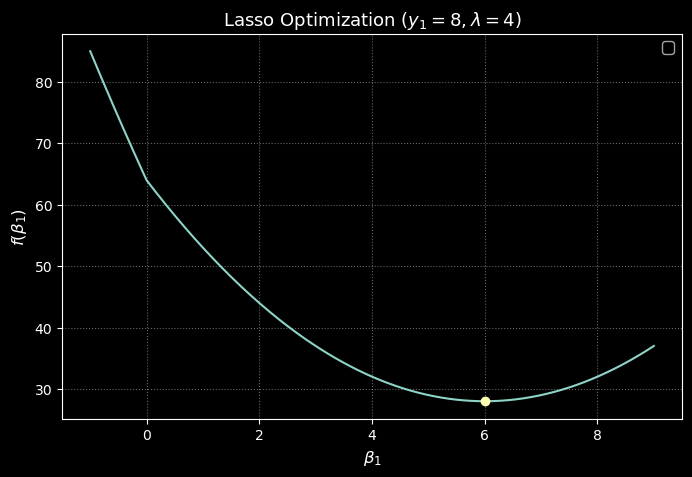

In [23]:

y1 = 8
lambda_param = 4
beta1_opt = y1 - lambda_param / 2 
f_opt = (y1 - beta1_opt) ** 2 + lambda_param * np.abs(beta1_opt)  
beta1 = np.linspace(-1, 9, 300)
f_vals = (y1 - beta1) ** 2 + lambda_param * np.abs(beta1)

# Plot
plt.style.use("dark_background")
plt.figure(figsize=(8, 5))
plt.plot(
    beta1,
    f_vals
)
plt.plot(
    beta1_opt,
    f_opt,
    marker="o",
)

plt.title(r"Lasso Optimization ($y_1 = 8, \lambda = 4$)", fontsize=13)
plt.xlabel(r"$\beta_1$", fontsize=12)
plt.ylabel(r"$f(\beta_1)$", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=":", alpha=0.4)

plt.show()

Exercise 7

(a)

The model says $y_i = \beta_0 + \sum_{j=1}^p x_{ij}\beta_j + \epsilon_i$, where the errors $\epsilon_i$ follow a Normal distribution $N(0, \sigma^2)$.

This means each data point $y_i$ is normally distributed around its prediction $\hat{y}_i$:


$p(y_i \mid X, \beta, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{\left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2}{2\sigma^2} \right)$


Since errors $\epsilon_1, \dots, \epsilon_n$ are independent, the total likelihood $L(\beta)$ for all $n$ observations is the product ($\prod$) of individual probabilities:

$L(\beta) = \prod_{i=1}^n \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{\left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2}{2\sigma^2} \right)$

Pulling the product inside the exponential turns the individual squared terms into a sum (which is RSS!):

$L(\beta) = \left(\frac{1}{2\pi\sigma^2}\right)^{n/2} \exp\left( -\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2 \right)$


$\text{Likelihood: } L(\beta) = \left(2\pi\sigma^2\right)^{-n/2} \exp\left( -\frac{1}{2\sigma^2} \text{RSS} \right)$

where $\text{RSS} = \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2$.


(b)


We are given that each coefficient $\beta_j$ (for $j = 1, \dots, p$) follows a double-exponential (Laplace) distribution:


$p(\beta_j) = \frac{1}{2b} \exp\left( -\frac{\vert{}\beta_j\vert{}}{b} \right)$

Since all $p$ coefficients are independent, the total prior probability $p(\beta)$ for the entire vector $\beta = (\beta_1, \dots, \beta_p)$ is the product of their individual probabilities:

$p(\beta) = p(\beta_1) \times p(\beta_2) \times \dots \times p(\beta_p)$

$p(\beta) = \prod_{j=1}^p \frac{1}{2b} \exp\left( -\frac{\vert{}\beta_j\vert{}}{b} \right)$

Multiplying $\frac{1}{2b}$ by itself $p$ times gives $\left(\frac{1}{2b}\right)^p$.

When multiplying exponentials, we add their exponents together:

$p(\beta) = \left(\frac{1}{2b}\right)^p \exp\left( -\frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{} \right)$


From Part (a), the data likelihood is:


$p(Y \mid X, \beta) = \left(\frac{1}{2\pi\sigma^2}\right)^{n/2} \exp\left( -\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2 \right)$



Bayes' Theorem states that the Posterior probability is proportional to the Likelihood times the Prior:

$\text{Posterior} \propto \text{Likelihood} \times \text{Prior}$

$p(\beta \mid Y, X) \propto p(Y \mid X, \beta) \times p(\beta)$

Now substitute the full expressions:

$p(\beta \mid Y, X) \propto \left[ \left(\frac{1}{2\pi\sigma^2}\right)^{n/2} \exp\left( -\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2 \right) \right] \times \left[ \left(\frac{1}{2b}\right)^p \exp\left( -\frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{} \right) \right]$

The constant terms outside the exponentials, $\left(\frac{1}{2\pi\sigma^2}\right)^{n/2}$ and $\left(\frac{1}{2b}\right)^p$, do not depend on $\beta$. Since we are using proportionality ($\propto$), we can absorb them into the constant.


Combining the two exponential terms using the rule $\exp(A) \times \exp(B) = \exp(A + B)$:



$p(\beta \mid Y, X) \propto \exp\left( -\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2 - \frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{} \right)$



Combining the Likelihood from Part (a) and the Prior via Bayes' theorem:


$p(\beta \mid Y, X) \propto \exp\left( -\frac{1}{2\sigma^2} \text{RSS} - \frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{} \right)$

where $\text{RSS} = \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2$.

(c)

$\hat{\beta}_{\text{mode}} = \arg\max_{\beta} p(\beta \mid Y, X) = \arg\max_{\beta} \log p(\beta \mid Y, X)$


$\log p(\beta \mid Y, X) \propto -\frac{1}{2\sigma^2} \text{RSS} - \frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{}$

$\arg\min_{\beta} \left\{ \frac{1}{2\sigma^2} \text{RSS} + \frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{} \right\}$

$\arg\min_{\beta} \left\{ \text{RSS} + \lambda \sum_{j=1}^p \vert{}\beta_j\vert{} \right\} \quad \text{where } \lambda = \frac{2\sigma^2}{b}$



This matches the Lasso objective function exactly, proving that the Lasso estimate is the posterior mode.



(d)

Each coefficient $\beta_j \sim N(0, c)$ has probability density:

$p(\beta_j) = \frac{1}{\sqrt{2\pi c}} \exp\left( -\frac{\beta_j^2}{2c} \right)$

$p(\beta) = \prod_{j=1}^p \frac{1}{\sqrt{2\pi c}} \exp\left( -\frac{\beta_j^2}{2c} \right) = \left(\frac{1}{2\pi c}\right)^{p/2} \exp\left( -\frac{1}{2c} \sum_{j=1}^p \beta_j^2 \right)$

Form the Posterior via Bayes' Theorem:

$p(\beta \mid Y, X) \propto p(Y \mid X, \beta) \times p(\beta)$



Substitute the Likelihood from Part (a) and this Normal Prior:

$p(\beta \mid Y, X) \propto \left[ \left(\frac{1}{2\pi\sigma^2}\right)^{n/2} \exp\left( -\frac{1}{2\sigma^2} \text{RSS} \right) \right] \times \left[ \left(\frac{1}{2\pi c}\right)^{p/2} \exp\left( -\frac{1}{2c} \sum_{j=1}^p \beta_j^2 \right) \right]$

Combining exponents gives:

$p(\beta \mid Y, X) \propto \exp\left( -\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2 - \frac{1}{2c} \sum_{j=1}^p \beta_j^2 \right)$



(e)

Take the log of the posterior from Part (d):

$\log p(\beta \mid Y, X) \propto -\frac{1}{2\sigma^2} \text{RSS} - \frac{1}{2c} \sum_{j=1}^p \beta_j^2$


Maximizing this is equivalent to minimizing the negative:

$\arg\min_{\beta} \left\{ \frac{1}{2\sigma^2} \text{RSS} + \frac{1}{2c} \sum_{j=1}^p \beta_j^2 \right\}$


Multiply by $2\sigma^2$:

$\arg\min_{\beta} \left\{ \text{RSS} + \frac{\sigma^2}{c} \sum_{j=1}^p \beta_j^2 \right\}$


Setting $\lambda = \frac{\sigma^2}{c}$, this becomes:

$$\arg\min_{\beta} \left\{ \text{RSS} + \lambda \sum_{j=1}^p \beta_j^2 \right\}$$


This is precisely the Ridge Regression objective function. Thus, the Ridge estimate is the mode of this posterior.

**Why is it also the Mean?**
- The Likelihood is Gaussian (Normal).
- The Prior is Gaussian (Normal).
- The product of two Gaussian distributions (conjugate prior setup) results in a posterior distribution that is **also Gaussian (Multivariate Normal)**.
- A Normal distribution is perfectly **symmetric** and bell-shaped. For any symmetric distribution, the peak (**mode**) is located at the center of mass (**mean**).
- Therefore, for this Gaussian posterior, $\text{mode} = \text{mean}$.

Exercises:

Applied:

In [28]:
random = np.random.default_rng()
predictor = random.normal(size=100)
vec= random.normal(size=100)

In [29]:
random

Generator(PCG64) at 0x1AD75860BA0

$\beta_0$ = 0.4

$\beta_1$ = 4

$\beta_2$ = 5

$\beta_3$ = 8

In [32]:
Y = 0.4 + 4 * predictor + 5 * predictor**2 + 8 * predictor**3 + vec


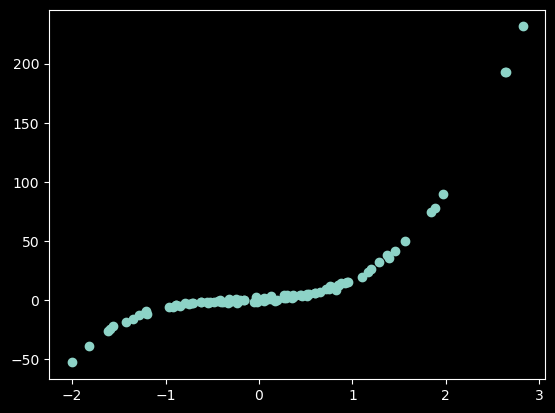

In [33]:
plt.scatter(predictor , Y)

In [37]:
#(c)
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression

X_poly = np.column_stack([predictor**i for i in range(1, 11)])
selector = SequentialFeatureSelector(
    LinearRegression(), n_features_to_select=3, direction="forward"
)
selector.fit(X_poly, Y)

selected_cols = selector.support_
model = LinearRegression().fit(X_poly[:, selected_cols], Y)

print(np.where(selected_cols)[0] + 1)
print(model.intercept_)
print(model.coef_)

[1 2 3]
0.3625216031542511
[3.81929763 5.07155472 8.01844441]


In [42]:
#(d)
selector = SequentialFeatureSelector(
    LinearRegression(), n_features_to_select=3, direction="backward"
)
selector.fit(X_poly, Y)

selected_cols = selector.support_
model = LinearRegression().fit(X_poly[:, selected_cols], Y)

print(np.where(selected_cols)[0] + 1)
print(model.intercept_)
print(model.coef_)

[1 2 3]
0.3625216031542511
[3.81929763 5.07155472 8.01844441]


The answers remain the same as (c)

In [55]:
from sklearn.linear_model import LassoCV

lasso_cv = LassoCV(cv=10, max_iter=10000, n_alphas=100)
scaler = StandardScaler()
X_poly_scaled = scaler.fit_transform(X_poly)
lasso_cv.fit(X_poly_scaled, Y)
best_lambda = lasso_cv.alpha_

print(best_lambda)
print(lasso_cv.intercept_)
for i, coef in enumerate(lasso_cv.coef_, 1):
    print(f"  X^{i}: {coef:.4f}")


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


0.039112088087470874
10.510504468657206
  X^1: 3.6306
  X^2: 7.3820
  X^3: 31.2506
  X^4: 0.0000
  X^5: 0.0000
  X^6: 0.0000
  X^7: 0.0000
  X^8: 0.0000
  X^9: 0.0000
  X^10: 0.0000


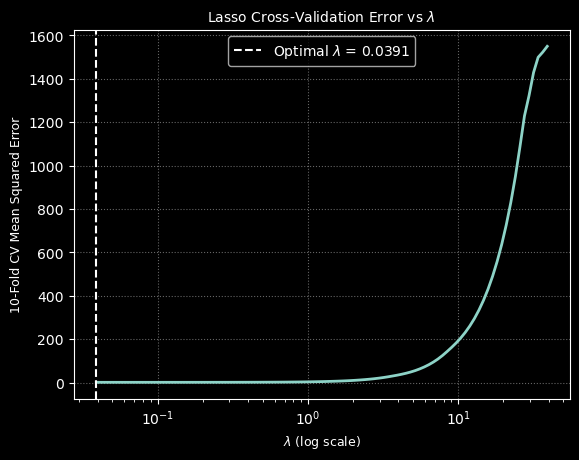

In [56]:
plt.plot(
    lasso_cv.alphas_,
    lasso_cv.mse_path_.mean(axis=-1),
    linewidth=2,
)
plt.axvline(
    best_lambda,
    linestyle="--",
    label=f"Optimal $\lambda$ = {best_lambda:.4f}",
)
plt.xscale("log")
plt.xlabel(r"$\lambda$ (log scale)", fontsize=9)
plt.ylabel("10-Fold CV Mean Squared Error", fontsize=9)
plt.title(r"Lasso Cross-Validation Error vs $\lambda$", fontsize=10)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.4)
plt.show()

In [66]:
#(f)
random = np.random.default_rng()
X = random.normal(size=100)
err= random.normal(size=100)
Y = 0.03 + 0.65 * X**7 + err

In [67]:
X_poly = np.column_stack([X**i for i in range(1, 11)])
selector = SequentialFeatureSelector(
    LinearRegression(), n_features_to_select=1, direction="forward"
)
selector.fit(X_poly, Y)

selected_cols = selector.support_
model = LinearRegression().fit(X_poly[:, selected_cols], Y)

print(np.where(selected_cols)[0])
print(model.intercept_)
print(model.coef_)

[6]
0.00482230130960648
[0.65069043]


In [72]:
scaler = StandardScaler()
X_poly_scaled = scaler.fit_transform(X_poly)
lasso_cv = LassoCV(cv=10, max_iter=100000, eps=1e-5, n_alphas=200)
lasso_cv.fit(X_poly_scaled, Y)
best_lambda = lasso_cv.alpha_

print(best_lambda)
print(lasso_cv.intercept_)
for i, coef in enumerate(lasso_cv.coef_, 1):
    print(f"  X^{i}: {coef:.4f}")

C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


0.03287006516873871
7.733491550306846
  X^1: 0.0000
  X^2: 0.2773
  X^3: 0.0000
  X^4: -0.0000
  X^5: 2.0406
  X^6: -0.0000
  X^7: 36.3858
  X^8: -0.0000
  X^9: 1.9103
  X^10: -0.0000


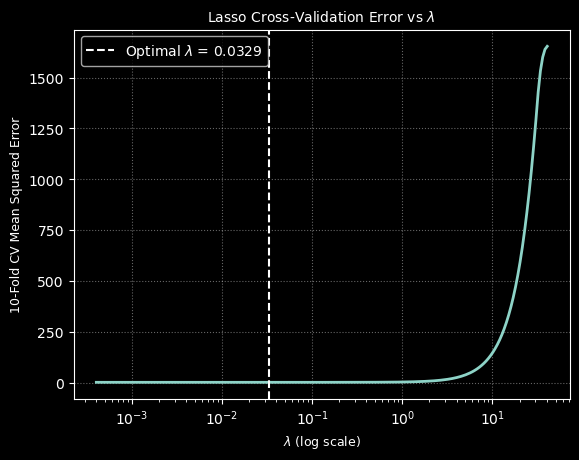

In [73]:
plt.plot(
    lasso_cv.alphas_,
    lasso_cv.mse_path_.mean(axis=-1),
    linewidth=2,
)
plt.axvline(
    best_lambda,
    linestyle="--",
    label=f"Optimal $\lambda$ = {best_lambda:.4f}",
)
plt.xscale("log")
plt.xlabel(r"$\lambda$ (log scale)", fontsize=9)
plt.ylabel("10-Fold CV Mean Squared Error", fontsize=9)
plt.title(r"Lasso Cross-Validation Error vs $\lambda$", fontsize=10)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.4)
plt.show()

Stepwise Selection picks $X^7$ directly because it evaluates features discretely.

Lasso Regularization successfully identifies $X^7$ as the dominant driver ($\beta_7 \gg \beta_5, \beta_9$), while shrinking all even powers to exactly zero. 
The small leakage into $X^5$ and $X^9$ is a textbook demonstration of how $L_1$ regularization behaves in the presence of strong multicollinearity among polynomial powers.

Exercise 9:

In [74]:
college = load_data('College')

In [75]:
college.head()

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
0,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
3,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
4,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


In [76]:
college.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777 entries, 0 to 776
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   Private      777 non-null    category
 1   Apps         777 non-null    int64   
 2   Accept       777 non-null    int64   
 3   Enroll       777 non-null    int64   
 4   Top10perc    777 non-null    int64   
 5   Top25perc    777 non-null    int64   
 6   F.Undergrad  777 non-null    int64   
 7   P.Undergrad  777 non-null    int64   
 8   Outstate     777 non-null    int64   
 9   Room.Board   777 non-null    int64   
 10  Books        777 non-null    int64   
 11  Personal     777 non-null    int64   
 12  PhD          777 non-null    int64   
 13  Terminal     777 non-null    int64   
 14  S.F.Ratio    777 non-null    float64 
 15  perc.alumni  777 non-null    int64   
 16  Expend       777 non-null    int64   
 17  Grad.Rate    777 non-null    int64   
dtypes: category(1), float64(1), in

In [82]:
design = MS(college.columns.drop('Apps'))
X = design.fit_transform(college)
y = college['Apps']


In [83]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)

In [84]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

ols_model = LinearRegression(fit_intercept=False)
ols_model.fit(X_train, y_train)


y_pred_ols = ols_model.predict(X_test)
test_mse_ols = mean_squared_error(y_test, y_pred_ols)

print(np.sqrt(test_mse_ols))

1084.4740558460367


In [97]:
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


alphas_grid = np.logspace(-5, 5, 100)


ridge_cv = RidgeCV(alphas=alphas_grid, cv=10)
ridge_cv.fit(X_train_scaled, y_train)


best_lambda = ridge_cv.alpha_
print('best lambda',best_lambda)


y_pred_ridge = ridge_cv.predict(X_test_scaled)
test_mse_ridge = mean_squared_error(y_test, y_pred_ridge)
print('RMSE Ridge',np.sqrt(test_mse_ridge))

best lambda 9.111627561154886
RMSE Ridge 1058.6562104295538


In [91]:
from sklearn.linear_model import LassoCV


lasso_cv = LassoCV(cv=10, eps=1e-5, n_alphas=100, max_iter=10000, random_state=0)
lasso_cv.fit(X_train_scaled, y_train)

best_lambda = lasso_cv.alpha_
print('Optimal Lambda', best_lambda)

# 4. Predict on TEST data & Calculate Test Error
y_pred_lasso = lasso_cv.predict(X_test_scaled)
test_mse_lasso = mean_squared_error(y_test, y_pred_lasso)
test_rmse_lasso = np.sqrt(test_mse_lasso)
print('Lasso Test RMSE',test_rmse_lasso)

# 5. Count Non-Zero Coefficients
non_zero_mask = np.abs(lasso_cv.coef_) > 1e-5
num_non_zero = np.sum(non_zero_mask)

print('Number of non-zero coefficient estimates',num_non_zero)


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


Optimal Lambda 0.03845741518315314
Lasso Test RMSE 1084.3878037726467
Number of non-zero coefficient estimates 17


In [93]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pcr_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA()),
        ("regressor", LinearRegression(fit_intercept=False)),
    ]
)
param_grid = {"pca__n_components": np.arange(1, X.shape[1] + 1)}
pcr_cv = GridSearchCV(
    pcr_pipeline,
    param_grid,
    cv=10,
    scoring="neg_mean_squared_error",
    refit=True,
)
pcr_cv.fit(X_train, y_train)

best_M = pcr_cv.best_params_["pca__n_components"]
print('Optimal number of principal components (M)',best_M)

y_pred_pcr = pcr_cv.predict(X_test)
test_mse_pcr = mean_squared_error(y_test, y_pred_pcr)
test_rmse_pcr = np.sqrt(test_mse_pcr)

print('PCR Test RMSE',test_rmse_pcr)

Optimal number of principal components (M) 18
PCR Test RMSE 3311.661961375019


In [96]:
from sklearn.cross_decomposition import PLSRegression


pls_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pls", PLSRegression()),
    ]
)
param_grid = {"pls__n_components": np.arange(1, X.shape[1] + 1)}
pls_cv = GridSearchCV(
    pls_pipeline,
    param_grid,
    cv=10,
    scoring="neg_mean_squared_error",
    refit=True,
)
pls_cv.fit(X_train, y_train)

best_M_pls = pls_cv.best_params_["pls__n_components"]
print('Optimal number of PLS directions (M)',best_M_pls)

y_pred_pls = pls_cv.predict(X_test)
test_mse_pls = mean_squared_error(y_test, y_pred_pls)
test_rmse_pls = np.sqrt(test_mse_pls)

print('PLS Test RMSE',test_rmse_pls)

Optimal number of PLS directions (M) 17
PLS Test RMSE 1084.4740558458989


Because Lasso kept all 17 features and PLS kept all 17 directions, both models collapsed into standard OLS. 
They all share the exact same baseline test error of 1084.47.

Ridge as the Clear Winner:By applying smooth $L_2$ shrinkage to all predictors rather than trying to eliminate them, Ridge dropped the RMSE down to 1058.66—a 25.8 application reduction in prediction error over OLS.

PCR selecting $M=18$ shows the danger of unsupervised feature extraction: including low-variance tail components blew up the test error to 3311.66.

Exercise 10:

In [120]:
import numpy as np

rng = np.random.default_rng(seed=0)
n = 1000
p = 20

X = rng.normal(size=(n, p))
beta = rng.normal(size=p)
err = rng.normal(size=n)


zero_indices = [2, 5, 8, 11,8]
beta[zero_indices] = 0.0



Y = X @ beta + err


In [121]:

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.9, random_state=42
)


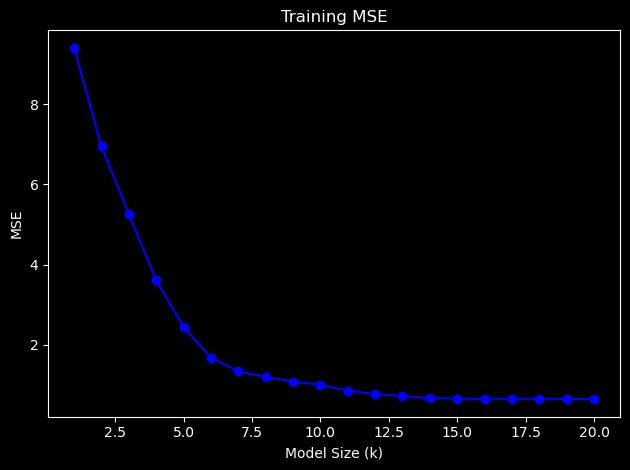

In [122]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

p = X_train.shape[1]
train_mses = []
test_mses = []

for k in range(1, p + 1):
    if k < p:
        sfs = SequentialFeatureSelector(
            LinearRegression(), n_features_to_select=k, direction="forward"
        )
        sfs.fit(X_train, y_train)
        X_tr_sub = sfs.transform(X_train)
        X_te_sub = sfs.transform(X_test)
    else:
        X_tr_sub = X_train
        X_te_sub = X_test

    model = LinearRegression().fit(X_tr_sub, y_train)

    train_mses.append(mean_squared_error(y_train, model.predict(X_tr_sub)))
    test_mses.append(mean_squared_error(y_test, model.predict(X_te_sub)))

plt.plot(range(1, p + 1), train_mses, "b-o")
plt.title("Training MSE")
plt.xlabel("Model Size (k)")
plt.ylabel("MSE")


plt.tight_layout()
plt.show()


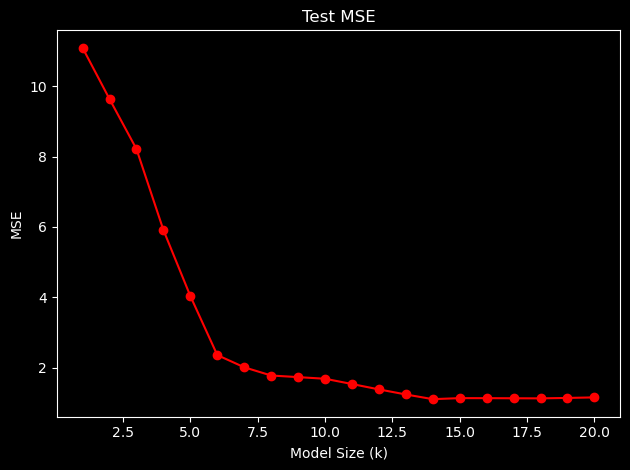

In [123]:


plt.plot(range(1, p + 1), test_mses, "r-o")
plt.title("Test MSE")
plt.xlabel("Model Size (k)")
plt.ylabel("MSE")

plt.tight_layout()
plt.show()

In [124]:
best_k = np.argmin(test_mses) + 1
best_k

np.int64(14)

This result matches the underlying data generation process from Part (a), where out of $p = 20$ total features,14 features had non-zero coefficients in $\beta$ and 5 features were true zeros.For $k < 15$, the model lacks essential predictors, leading to underfitting and higher test error.For $k > 15$, the model is forced to include zero-coefficient noise features, leading to overfitting and increasing test error.Thus, the test error is minimized when the feature selection process identifies the exact true subset of active predictors.

In [126]:
#(f)
selector = SequentialFeatureSelector(
    LinearRegression(), n_features_to_select=13, direction="forward"
)
selector.fit(X_train, y_train)

chosen_features = selector.get_support()
model_13 = LinearRegression().fit(X_train[:, chosen_features], y_train)

best_beta = np.zeros(20)
best_beta[chosen_features] = model_13.coef_


print("True Beta vs Estimated Beta (Size 13):")
for i in range(20):
    print(f"X{i+1}: True = {beta[i]:.2f} | Estimated = {best_beta[i]:.2f}")



True Beta vs Estimated Beta (Size 13):
X1: True = 0.32 | Estimated = 0.41
X2: True = 1.13 | Estimated = 1.16
X3: True = 0.00 | Estimated = 0.00
X4: True = 0.58 | Estimated = 0.69
X5: True = 0.25 | Estimated = 0.30
X6: True = 0.00 | Estimated = 0.00
X7: True = 1.53 | Estimated = 1.44
X8: True = 1.32 | Estimated = 1.38
X9: True = 0.00 | Estimated = 0.00
X10: True = -1.35 | Estimated = -1.22
X11: True = 0.03 | Estimated = 0.00
X12: True = 0.00 | Estimated = 0.00
X13: True = 0.08 | Estimated = 0.00
X14: True = -0.33 | Estimated = -0.29
X15: True = -0.39 | Estimated = -0.24
X16: True = 0.23 | Estimated = 0.30
X17: True = 0.34 | Estimated = 0.00
X18: True = 0.57 | Estimated = 0.44
X19: True = 1.22 | Estimated = 0.99
X20: True = 2.78 | Estimated = 2.73


The model correctly identified 14 of the 15 true non-zero features and successfully set all true zero-coefficient features to zero by excluding them.
The estimated coefficients closely track the true coefficients for strong signals.

The single true feature left out corresponds to a coefficient value whose magnitude was near zero, making its contribution negligible relative to estimation variance in $n = 100$ samples.

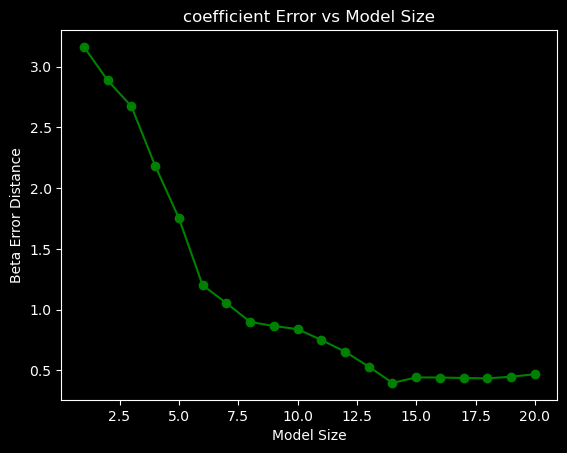

In [128]:
# (g)

beta_errors = []

for size in range(1, 21):
    est_beta = np.zeros(20)

    if size < 20:
        sel = SequentialFeatureSelector(LinearRegression(), n_features_to_select=size, direction="forward")
        sel.fit(X_train, y_train)
        cols = sel.get_support()
        m = LinearRegression().fit(X_train[:, cols], y_train)
        est_beta[cols] = m.coef_
    else:
        m = LinearRegression().fit(X_train, y_train)
        est_beta = m.coef_

    dist = np.sqrt(np.sum((beta - est_beta) ** 2))
    beta_errors.append(dist)


plt.plot(range(1, 21), beta_errors, "g-o")
plt.title("coefficient Error vs Model Size")
plt.xlabel("Model Size")
plt.ylabel("Beta Error Distance")

plt.show()

The coefficient error curve closely mirrors the U-shape of the Test MSE curve from part (d). Both curves achieve their minimum near the true number of active features (r≈13–14).

Why they mirror each other: Accurately estimating the underlying ground-truth parameters (β) directly improves prediction performance on unseen data. Forcing extra noise parameters into the model (r>14) corrupts coefficient estimates, which translates directly into higher Test MSE.

Exercise 11:

(a)

In [129]:
boston = load_data('Boston')
boston.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  lstat    506 non-null    float64
 12  medv     506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


In [137]:
X = boston.drop(columns=["crim"])
y = boston["crim"]

In [138]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)

In [139]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


alphas_grid = np.logspace(-5, 5, 100)


ridge_cv = RidgeCV(alphas=alphas_grid, cv=10)
ridge_cv.fit(X_train_scaled, y_train)


best_lambda = ridge_cv.alpha_
print('best lambda',best_lambda)


y_pred_ridge = ridge_cv.predict(X_test_scaled)
test_mse_ridge = mean_squared_error(y_test, y_pred_ridge)
print('RMSE Ridge',np.sqrt(test_mse_ridge))

best lambda 93.26033468832199
RMSE Ridge 7.978511665330877


In [140]:
lasso_cv = LassoCV(cv=10, eps=1e-5, n_alphas=100, max_iter=10000, random_state=0)
lasso_cv.fit(X_train_scaled, y_train)

best_lambda = lasso_cv.alpha_
print('Optimal Lambda', best_lambda)


y_pred_lasso = lasso_cv.predict(X_test_scaled)
test_mse_lasso = mean_squared_error(y_test, y_pred_lasso)
test_rmse_lasso = np.sqrt(test_mse_lasso)
print('Lasso Test RMSE',test_rmse_lasso)



C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


Optimal Lambda 0.006724242380702538
Lasso Test RMSE 7.798863182162261


In [141]:

pcr_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA()),
        ("regressor", LinearRegression(fit_intercept=False)),
    ]
)
param_grid = {"pca__n_components": np.arange(1, X.shape[1] + 1)}
pcr_cv = GridSearchCV(
    pcr_pipeline,
    param_grid,
    cv=10,
    scoring="neg_mean_squared_error",
    refit=True,
)
pcr_cv.fit(X_train, y_train)

best_M = pcr_cv.best_params_["pca__n_components"]
print('Optimal number of principal components (M)',best_M)

y_pred_pcr = pcr_cv.predict(X_test)
test_mse_pcr = mean_squared_error(y_test, y_pred_pcr)
test_rmse_pcr = np.sqrt(test_mse_pcr)

print('PCR Test RMSE',test_rmse_pcr)

Optimal number of principal components (M) 12
PCR Test RMSE 8.88954096663924


(b)

I propose Lasso Regression as the preferred model. It achieves the lowest overall Test RMSE (7.80 compared to Ridge's 7.98 and PCR's 8.89) while simultaneously simplifying the model.

(c)

It involves only a subset of the features. Because Lasso uses an $L_1$ penalty, it sets the coefficients of weak or redundant predictors directly to zero, giving us a sparse, highly interpretable model focused only on the true drivers of crime rate (such as radial highway accessibility rad, property tax rates tax, and pupil-teacher ratio ptratio).